# Leaf traits inversion

The objective of this tutorial is to estimate leaf traits from reflectance data using the PROSPECT model.

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import prosail

In [9]:
LEAF_TRAITS = {
    'N': {'desc': 'Leaf structure parameter', 'range': [1.0, 2.5], 'default': 1.5, 'unit': None},
    'Cab': {'desc': 'Chlorophyll a+b concentration', 'range': [20, 80], 'default': 40, 'unit': 'µg/cm²'},
    'Car': {'desc': 'Cartenoid concentration', 'range': [3, 15], 'default': 8, 'unit': 'µg/cm²'},
    'Cbrown': {'desc': 'Brown pigment', 'range': [0, 1], 'default': 0, 'unit': None},
    'Cw': {'desc': 'Equivalent water thickness', 'range': [0.005, 0.04], 'default': 0.015, 'unit': 'cm'},
    'Cm': {'desc': 'Dry matter', 'range': [0.002, 0.02], 'default': 0.009, 'unit': 'g/cm²'}
}

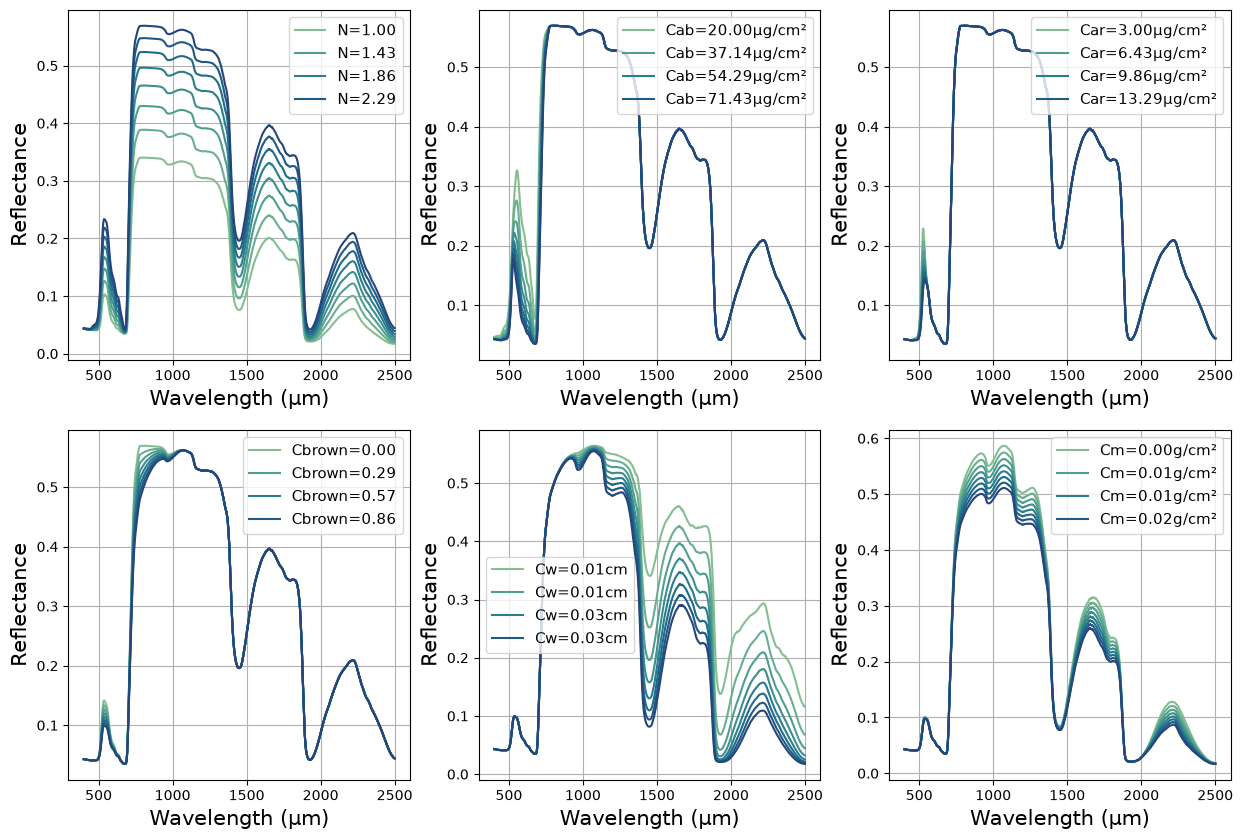

In [10]:
n_values = 8
fontsize = 15

colors = sns.color_palette("crest", n_values)
traits = dict((k, v['default']) for k, v in LEAF_TRAITS.items())

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for trait, ax in zip(LEAF_TRAITS, axs.flat):
    range_trait = LEAF_TRAITS[trait]['range']
    trait_values = np.linspace(range_trait[0], range_trait[1], n_values)
    for i, trait_value in enumerate(trait_values):
        traits[trait] = trait_value
        lam, rho, tau = prosail.run_prospect(traits['N'], traits['Cab'], traits['Car'], traits['Cbrown'], traits['Cw'], traits['Cm'])
        unit = LEAF_TRAITS[trait]['unit'] if LEAF_TRAITS[trait]['unit'] is not None else ''
        label = f'{trait}={trait_value:.2f}{unit}' if i % 2 == 0 else None
        ax.plot(lam, rho, color=colors[i], label=label)
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()
plt.show()

## Variations of local irradiance

In [24]:
import os
import sys
import glob 

sys.path.append('../basics_radiative_transfer_modeling')

from eodal_s2_parsing import parse_MTD_TL
from parse_auxiliary_data import get_atmosphere_data
from radiative_transfer_modeling import radiative_transfer_modeling_6S

data_folder = '../../../../data/S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_20261005T140445.SAFE/'

aux_geometry_data = parse_MTD_TL(glob.glob(os.path.join(data_folder, 'GRANULE/*/MTD_TL.xml'))[0])

aux_atmosphere_data = get_atmosphere_data(
    data_folder,
    lat=aux_geometry_data['ULX'],
    lon=aux_geometry_data['ULY'])

aux_data = {
    'AUX_GEOMETRY_DATA': aux_geometry_data,
    'AUX_ATMOSPHERIC_DATA': aux_atmosphere_data
}

radiative_variables = radiative_transfer_modeling_6S(aux_data, lam[::6] / 1000)

ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represen

In [25]:
traits = dict((k, v['default']) for k, v in LEAF_TRAITS.items())
lam, rho, tau = prosail.run_prospect(traits['N'], traits['Cab'], traits['Car'], traits['Cbrown'], traits['Cw'], traits['Cm'])

lam, rho = lam[::6], rho[::6]

In [30]:
theta = aux_data['AUX_GEOMETRY_DATA']['SUN_ZENITH_ANGLE']
I_dir = np.array(radiative_variables['DIRECT_SOLAR_IRRADIANCE']['VALUES'])
I_dif = np.array(radiative_variables['DIFFUSE_SOLAR_IRRADIANCE']['VALUES'])
print(f"Sun zenith angle: {theta:.2f}deg")
theta = theta * np.pi / 180

Sun zenith angle: 53.95deg


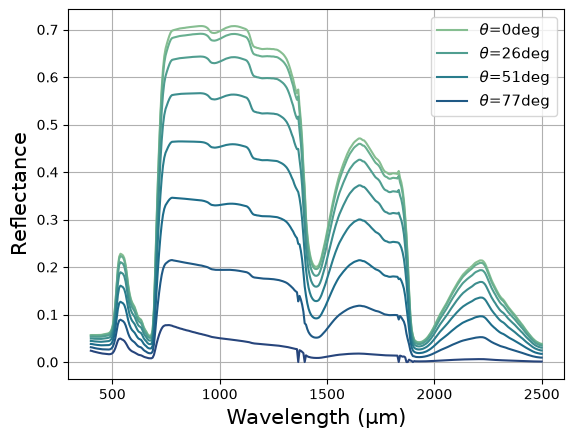

In [35]:
fig, ax = plt.subplots()
for i, theta_true in enumerate(np.linspace(0, np.pi / 2, n_values)):
    rho_hat = (I_dir * np.cos(theta_true) + I_dif) / (I_dir * np.cos(theta) + I_dif) * rho
    label = r'$\theta$' + f'={theta_true * 180 / np.pi:.0f}deg' if i % 2 == 0 else None
    ax.plot(lam, rho_hat, color=colors[i], label=label)
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
ax.legend(fontsize=int(0.75*fontsize))
ax.grid()
plt.show()

## Look-up Table

In [152]:
def leaf_traits_table(
    variables: List,
    n_values: int,
):
    """ Uniformly sample leaf traits given intervals.
    
    Args:
        variables: list of leaf traits
        n_values : size of the range for every traits

    Returns:
        a np.ndarray of size n_values**(len(variables)) x len(variables)
    """
    trait_ranges = []
    for i, trait in enumerate(LEAF_TRAITS):
        range_trait = LEAF_TRAITS[trait]['range']
        trait_values = np.linspace(range_trait[0], range_trait[1], n_values)
        shape = [1] * len(variables)
        shape[i] = n_values
        final_shape = (n_values,) * len(variables)
        trait_ranges.append(np.broadcast_to(trait_values.reshape(shape), final_shape))
    trait_ranges = np.stack(trait_ranges) #shape = (len(variables),) + (n_values,) * len(variables)
    traits_table = trait_ranges.reshape(len(variables), -1).T
    return traits_table
    
def compute_LUT(
    variables: List,
    n_values: int,
    n_bands: int = 351
):
    """ Computes a Look-Up Table.
    
    Args:
        variables: list of leaf traits
        n_values : size of the range for every traits
        n_bands: number of spectral channels.

    Returns:
        a np.ndarray of size n_values**(len(variables)) x len(variables)
    """
    size = n_values**len(variables)
    reflectance_table = np.zeros((size, n_bands))
    traits_table = leaf_traits_table(variables, n_values)
    for i in range(size):
        _, rho, _ = prosail.run_prospect(
            traits_table[i, 0],
            traits_table[i, 1],
            traits_table[i, 2],
            traits_table[i, 3],
            traits_table[i, 4],
            traits_table[i, 5],
        )
        reflectance_table[i] = rho[::6]
    return traits_table, reflectance_table

In [153]:
traits = list(LEAF_TRAITS.keys())
traits_table, reflectance_table = compute_LUT(traits, n_values=6)

In [163]:
import random

new_traits = dict((k, random.uniform(v['range'][0], v['range'][1])) for (k, v) in LEAF_TRAITS.items())
 
lam, rho, _ = prosail.run_prospect(
    new_traits['N'], 
    new_traits['Cab'], 
    new_traits['Car'], 
    new_traits['Cbrown'], 
    new_traits['Cw'], 
    new_traits['Cm']
)

lam, rho = lam[::6], rho[::6]

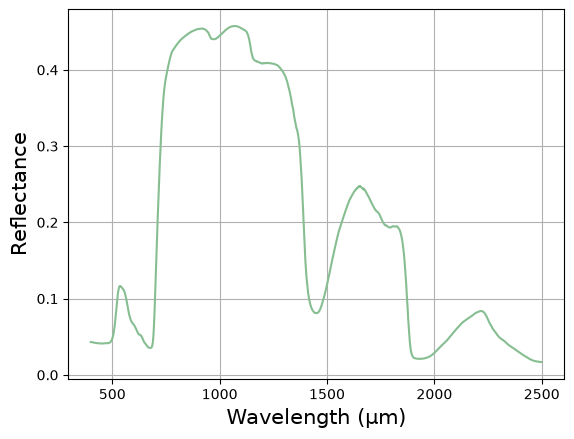

In [160]:
fig, ax = plt.subplots()
ax.plot(lam, rho, color=colors[0], label=label)
ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
ax.set_ylabel('Reflectance', fontsize=fontsize)
ax.grid()
plt.show()

In [171]:
def spectral_distance(spectrum, spectra):
    spectrum = spectrum.reshape(1, -1)
    dist = np.sqrt(np.sum((spectrum - spectra)**2, axis=-1))
    return dist

dist = spectral_distance(rho, reflectance_table)
closest_spectra_indices = np.argsort(dist)
closest_spectra_top_3 = reflectance_table[closest_spectra_indices[:3]]

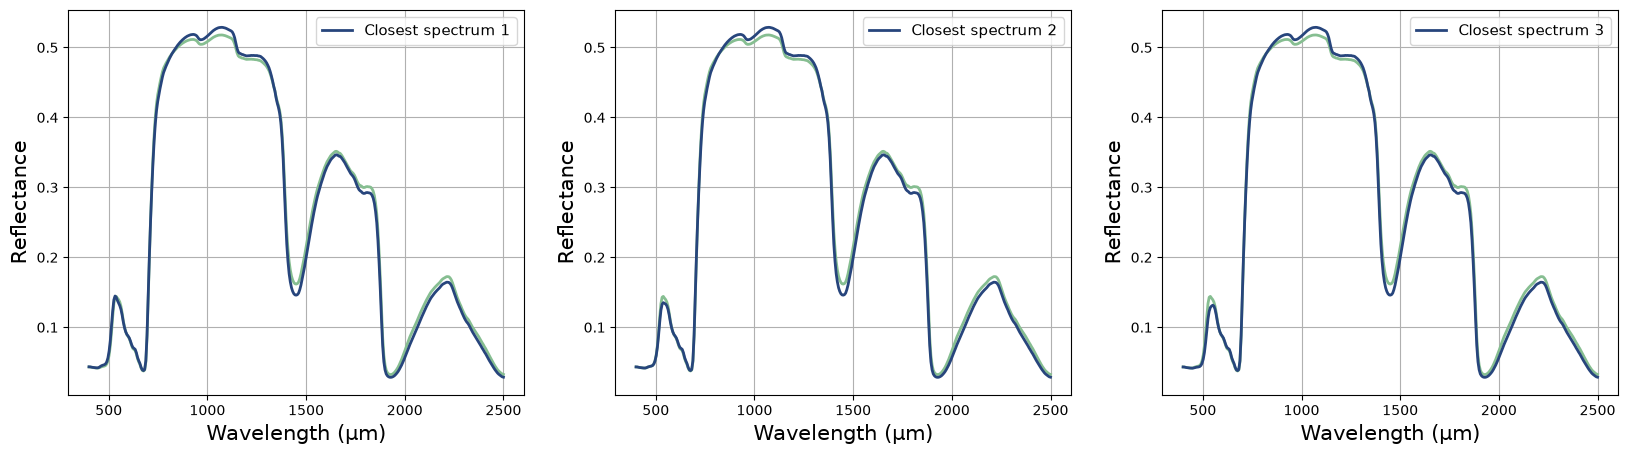

In [180]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i, ax in enumerate(axs.flat):
    ax.plot(lam, rho, color=colors[0], lw=2)
    ax.plot(lam, closest_spectra_top_3[i], color=colors[-1], lw=2, label=f'Closest spectrum {i+1}')
    ax.legend(fontsize=int(0.75*fontsize))
    ax.grid()
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel('Reflectance', fontsize=fontsize)
plt.show()

In [181]:
closest_leaf_traits = traits_table[closest_spectra_indices[:3]]
print(closest_leaf_traits)

[[2.20e+00 4.40e+01 5.40e+00 8.00e-01 1.90e-02 9.20e-03]
 [2.20e+00 4.40e+01 7.80e+00 8.00e-01 1.90e-02 9.20e-03]
 [2.20e+00 4.40e+01 1.02e+01 8.00e-01 1.90e-02 9.20e-03]]


In [182]:
# to sentinel 2 resolution

In [183]:
# on a real image